# A metal complex: a redox potential, and what the metal breaks

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/09_a_metal_complex.ipynb)

The earlier notebooks model organic molecules. A **coordination complex** has a metal atom in its
centre. Atoms of the ligands, the **donor atoms**, are bonded to the metal. Together they form the
**first coordination sphere**. The program was not made for such a molecule, and a metal breaks
three things in it without any message. This notebook does three things.

1. It shows the three faults and the three checks that find them. Each check takes a second.
2. It builds the frame from the metal, which is the one atom that every complex of a series has.
3. It asks the question of the notebooks before it: what does a field model add to a number that
   is much cheaper to get? Here that number is the composition of the complex.

There are two series. **Nickel**: 25 complexes with one ligand skeleton and one coordination sphere,
which differ in their substituents. **Iron**: 2216 complexes that share the metal and nothing else.
The targets are redox potentials, computed with density functional theory and not measured. So the
question is how well a description orders complexes that one calculation produced.

Running time: about three minutes.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## Two series of complexes

The files are `examples/complexes_ni/ni_bpp.sdf` and `examples/complexes_fe/fe_redox.sdf`. The
program that reads them is `benchmarks/run_metal.py`, the script that measured these series for the
manual. The notebook uses its functions, so that every number can be compared with the table
`benchmarks/results/metal/table.md`. The kernel cache of the benchmarks is switched off, so nothing
is written to the repository.

                      complexes  atoms each    different spheres potential, mean +/- sd (V)
nickel, oxidation            25        46.7                    1           1.99 +/- 0.56
nickel, reduction            25        46.7                    1          -0.18 +/- 0.06
iron, reduction            2216        50.1                  377           0.57 +/- 0.66


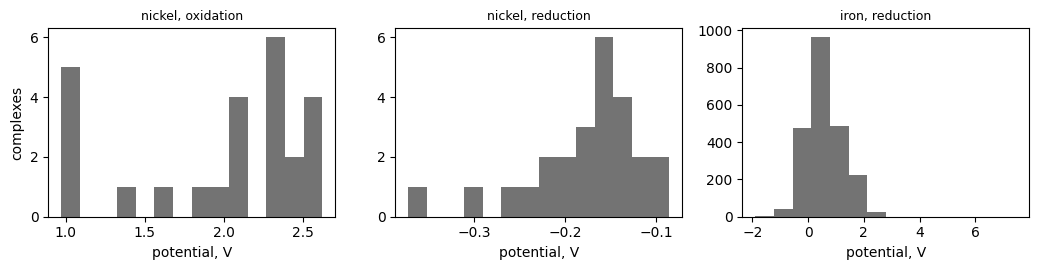

the two largest iron potentials: 7.48 V and 2.81 V


In [2]:
import contextlib
import io
import os
import sys

os.environ["CMF_KERNEL_CACHE"] = "0"
sys.path.insert(0, "benchmarks")

import matplotlib.pyplot as plt
import numpy as np
from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem

RDLogger.DisableLog("rdApp.*")
import run_metal as rm            # loaders, models, folds and intervals of the series

nickel, nickel_names, nickel_y = rm.load(rm.NICKEL_SDF, rm.NICKEL_TARGETS)
iron, iron_names, iron_y = rm.load(rm.IRON_SDF, [rm.IRON_TARGET])
y_iron = iron_y[rm.IRON_TARGET]
spheres = [m.GetProp("donors") for m in iron]

series = [("nickel, oxidation", nickel, nickel_y["E_ox_AN"]),
          ("nickel, reduction", nickel, nickel_y["E_red_AN"]),
          ("iron, reduction", iron, y_iron)]
print("%-20s %10s %11s %20s %24s" % ("", "complexes", "atoms each", "different spheres", "potential, mean +/- sd (V)"))
for label, mols, y in series:
    print("%-20s %10d %11.1f %20d %14.2f +/- %.2f" % (label, len(mols), np.mean([m.GetNumAtoms() for m in mols]),
                                                    len({m.GetProp("donors") for m in mols}), y.mean(), y.std()))

fig, axes = plt.subplots(1, 3, figsize=(10.5, 2.8))
for ax, (label, mols, y) in zip(axes, series):
    ax.hist(y, bins=14, color="0.45")
    ax.set_title(label, fontsize=9)
    ax.set_xlabel("potential, V")
axes[0].set_ylabel("complexes")
plt.tight_layout()
plt.show()
print("the two largest iron potentials: %.2f V and %.2f V" % tuple(sorted(y_iron)[-1:-3:-1]))

The nickel complexes all have the coordination sphere N3O3: three nitrogen donors of one ligand and
three water molecules. The oxidation potential varies over 1.7 V. The reduction potential of the
other couple varies over only 0.29 V, and its standard deviation is 0.06 V, so there is little to
predict. The 2216 iron complexes have 377 different spheres. One of them has a potential of
7.48 V, far from the rest.

A complex is stored with **dative bonds** from every donor to the metal. A dative bond points from
the donor to the metal and carries no electron of the donor's own valence, so the donor keeps the
valence that it has in the free ligand. Here is the first nickel complex.

In [3]:
from cmfqsar.complexes import coordination

complex_ = nickel[0]
dative = sum(1 for b in complex_.GetBonds() if b.GetBondType() == Chem.BondType.DATIVE)
print("the first nickel complex: %d atoms, %d dative bonds" % (complex_.GetNumAtoms(), dative))
print({key: round(value, 2) for key, value in coordination(complex_).items()})

the first nickel complex: 35 atoms, 6 dative bonds
{'n_donors': 6.0, 'metal_charge': 2.0, 'd_min': 2.02, 'd_mean': 2.11, 'd_max': 2.16, 'donor_N': 3.0, 'donor_O': 3.0}


## Three things that a metal breaks, quietly

Each of the three gives numbers, and none gives an error message. So each one has a check.

**1. The charges.** The electrostatic field needs a charge on every atom. The scheme of the program
(Gasteiger) has no parameters for a metal, and one metal atom makes it return "not a number" for
*every* atom of the molecule. Without a repair, the electrostatic field of a complex is zero.

In [4]:
def plain_gasteiger_gives_nothing(mol):
    work = Chem.Mol(mol)
    AllChem.ComputeGasteigerCharges(work)
    charges = [float(a.GetProp("_GasteigerCharge")) if a.HasProp("_GasteigerCharge") else float("nan")
               for a in work.GetAtoms()]
    return not np.any(np.isfinite(charges))


print("plain Gasteiger charges are all 'not a number' for %d of %d nickel complexes" % (
    sum(plain_gasteiger_gives_nothing(m) for m in nickel), len(nickel)))
print("                                          and for %d of the first 200 iron complexes" % (
    sum(plain_gasteiger_gives_nothing(m) for m in iron[:200])))

from cmfqsar.fields import FieldSet, build_fields

fieldset = FieldSet.create(physchem=list(rm.FIELDS), alpha=1.0, charge_model="gasteiger", param_scheme="rdkit")
fields = build_fields(nickel[0], fieldset, "ni_01")
symbols = list(fields.symbols)
print()
print("the program, for the first nickel complex: charge source '%s'" % fields.charge_source)
print("charge on the nickel atom %+.3f; all charges add up to %+.3f; the charge of the complex is %+d" % (
    fields.charges[symbols.index("Ni")], fields.charges.sum(), int(nickel[0].GetProp("charge"))))

plain Gasteiger charges are all 'not a number' for 25 of 25 nickel complexes


                                          and for 197 of the first 200 iron complexes

the program, for the first nickel complex: charge source 'gasteiger+formal'
charge on the nickel atom +2.000; all charges add up to +2.000; the charge of the complex is +2


The program computes the charges of the ligands with the metal taken out, and gives the metal its
formal charge. The source is then called `gasteiger+formal`, so that a model fitted on these
charges cannot be taken for one fitted on plain `gasteiger` charges. This repair does not describe
the donation of electrons from the ligand to the metal. The donor atoms are less polarised than
they really are. A calculated charge per atom would be better where there is one.

**2. A ligand of one atom.** A chloride, bromide or iodide ligand has no bond whose order could be
found. Bond perception leaves such an atom neutral whatever charge it is given, and the charge of
the halide then goes to the metal. The complex has the right total charge and the wrong charge
inside it. In the iron series 771 of 2216 complexes have such a ligand. The check is that the formal
charges add up to the stated charge of the complex, and that the halide has its own charge.

In [5]:
halide = [m for m in iron if any(a.GetSymbol() in ("Cl", "Br", "I") and a.GetDegree() == 1 for a in m.GetAtoms())]
disagree = sum(sum(a.GetFormalCharge() for a in m.GetAtoms()) != int(float(m.GetProp("charge"))) for m in iron)
print("iron complexes with a halide ligand: %d of %d" % (len(halide), len(iron)))
print("complexes whose formal charges do not add up to the stated charge: %d" % disagree)

right = iron[0]
wrong = Chem.RWMol(right)                      # the same complex, with the fault: the halide neutral, the metal one charge less
for atom in wrong.GetAtoms():
    if atom.GetSymbol() == "I":
        atom.SetFormalCharge(0)
    if atom.GetSymbol() == "Fe":
        atom.SetFormalCharge(atom.GetFormalCharge() - 1)
wrong = wrong.GetMol()
Chem.SanitizeMol(wrong)
print()
print("%-28s %12s %12s" % ("complex " + iron_names[0] + ", charge %+d" % int(right.GetProp("charge")), "iron", "iodine"))
for label, mol in (("as stored", right), ("with the halide fault", wrong)):
    f = build_fields(mol, fieldset, label)
    s = list(f.symbols)
    print("%-28s %+12.3f %+12.3f" % (label, f.charges[s.index("Fe")], f.charges[s.index("I")]))

iron complexes with a halide ligand: 771 of 2216
complexes whose formal charges do not add up to the stated charge: 0

complex ABAXIK, charge +1            iron       iodine
as stored                          +2.000       -1.000
with the halide fault              +1.000       -0.107


The total charge is +1 in both files, and the electrostatic field of the second is the field of
another molecule: the iron carries +1 and not +2, and the iodine carries a tenth of its charge.
The builder now writes the stated charge onto a one-atom ligand. The files of this repository are
free of the fault. A new data set should be checked in the same way.

**3. The size of the metal.** The table of van der Waals radii of the steric field stops at the main
group. A metal got the default radius of 1.80 Å, larger than a carbon atom. The program now takes the
metal radii from the universal force field, put on the scale of the carbon radius. A metal also gets
no hydrophobic and no hydrogen-bond weight, because those increments were fitted to organic molecules.

In [6]:
from cmfqsar.atomtypes import vdw_params

print("van der Waals radius in angstrom: " + ", ".join("%s %.3f" % (s, vdw_params(s)[0]) for s in ("C", "N", "O", "Fe", "Ni")))

van der Waals radius in angstrom: C 1.700, N 1.550, O 1.520, Fe 1.285, Ni 1.251


The three checks, for any set with a metal: the charge source is not plain `gasteiger`, the formal
charges add up to the charge of every complex, and the metal has a radius of its own. A model fitted on
a complex whose electrostatic field is zero still runs and still gives a score. It is a model of four
fields, and nothing in the score says so.

## The frame that the metal gives

The earlier notebooks put every molecule in a frame by a rule or by a fit. A complex series has an
atom in common, the metal. So the metal goes to the origin, and only the rotation is left.

- **Matching the donors.** For a series with one coordination sphere, each complex is turned so that
  its donor atoms lie as close as possible to those of a reference complex. The assignment of
  donors to donors is not known, so every assignment between atoms of the same element is tried.
- **A rule.** For a series with different spheres there is nothing to match. The principal axes of the
  whole complex give the frame, with the signs fixed by the third moment. The function also reports
  the gap between the two smallest moments. A small gap means that the frame is arbitrary in that
  plane.

In [7]:
from cmfqsar.complexes import donor_indices

matched = np.array([float(m.GetProp("donor_rmsd")) for m in nickel])
by_rule, gaps_nickel = rm.framed(nickel)
reference = nickel[0].GetConformer().GetPositions()[donor_indices(nickel[0])]
rule = np.array([np.sqrt(np.mean(np.sum((m.GetConformer().GetPositions()[donor_indices(m)] - reference) ** 2, axis=1)))
                 for m in by_rule])
print("nickel, six donors of every complex:")
print("  the file's frame (matched donors): mean distance of the donors from the reference %.2f A, worst %.2f A" % (matched.mean(), matched.max()))
print("  the rule frame:                    mean distance of the donors from the reference %.2f A, worst %.2f A" % (rule.mean(), rule.max()))
_, gaps_iron = rm.framed(iron)
print("iron: the gap of the rule frame is below 0.05 (nearly degenerate) for %.0f %% of the 2216 complexes" % (100 * np.mean(gaps_iron < 0.05)))

nickel, six donors of every complex:
  the file's frame (matched donors): mean distance of the donors from the reference 0.03 A, worst 0.23 A
  the rule frame:                    mean distance of the donors from the reference 1.82 A, worst 3.45 A


iron: the gap of the rule frame is below 0.05 (nearly degenerate) for 11 % of the 2216 complexes


For nickel the matched frame is a real shared frame: the donors lie 0.03 Å from each other on the
average. The rule puts the same donors 1.82 Å from there. The rule is pulled around by the
substituents, which differ from complex to complex, and the match uses only the atoms that every
member shares. For iron no match is possible across the whole series, and the rule is nearly
degenerate for one complex in nine.

## Nickel: the oxidation potential, and what one number says

The question of this series is the one of the gate of its study: does a model of five fields beat
a model of numbers from the same calculation? The numbers are the natural population analysis of
the calculation that produced the potential: the charge and the spin on the metal, on the ligand
and on the waters. Before the models, the cheap references. The composition of a complex is
the number of atoms of each element, the number of atoms, the charge, and the first sphere
(number of donors, shortest, mean and longest distance from the metal). The next cell gives
the leave-one-out q² of a linear regression on **one** of these numbers, for each that varies.

In [8]:
elements = rm.element_columns(nickel)
labels = ["%s atoms" % e for e in elements] + ["all atoms", "charge", "donors", "charge of the metal",
                                              "shortest metal-donor distance", "mean metal-donor distance",
                                              "longest metal-donor distance"] + ["%s donors" % e for e in elements]
composition = rm.composition_matrix(nickel, elements)
y = nickel_y["E_ox_AN"]


def loo_q2(column, y):
    predicted = np.empty(len(y))
    for i in range(len(y)):
        train = np.delete(np.arange(len(y)), i)
        slope, intercept = np.polyfit(column[train], y[train], 1)
        predicted[i] = slope * column[i] + intercept
    return 1.0 - np.sum((y - predicted) ** 2) / np.sum((y - y.mean()) ** 2)


print("%-32s %12s %8s" % ("one number per complex", "correlation", "q2"))
for label, column in zip(labels, composition.T):
    if column.std() > 1e-9:
        print("%-32s %+12.2f %+8.2f" % (label, np.corrcoef(column, y)[0, 1], loo_q2(column, y)))

one number per complex            correlation       q2
C atoms                                 -0.78    +0.53
H atoms                                 -0.84    +0.64
N atoms                                 -0.91    +0.76
O atoms                                 +0.13    -0.10
all atoms                               -0.86    +0.66
shortest metal-donor distance           +0.62    +0.26
mean metal-donor distance               -0.27    -0.07
longest metal-donor distance            -0.36    +0.01


The number of nitrogen atoms alone reaches a q² of 0.76. It is the best of eight numbers, so the
value is too high as an estimate. Still, it says that the substituents of this series differ in
their nitrogen, and that the oxidation potential follows. Now the six models, with the ridge
parameter and the width of the fields chosen inside the training part of each fold.

- `composition`: all the numbers above, in one model.
- `quantum`: the population analysis of the calculation of the target.
- `site`: the first sphere alone. Every complex has N3O3, so only the distances differ.
- `fields, no frame`: the rotation-invariant kernel of the five fields (second notebook).
- `fields, matched frame`: the overlap kernel of the five fields in the frame of matched donors.
- `fields, rule frame`: the same kernel in the frame of the rule.

Two designs are used. With **leave-one-out** every complex is predicted by a model fitted to the
other 24. With **five random folds** a model is fitted to 20.

In [9]:
model_names = {"composition": "composition", "quantum": "quantum", "site": "site", "invariant": "fields, no frame",
               "physchem": "fields, matched frame", "overlap-rule": "fields, rule frame"}
prepared = {model: rm.prepare(model, nickel, nickel_names, elements) for model in model_names}
designs = {"leave-one-out": rm.leave_one_out(len(nickel)), "five random folds": rm.random_folds(len(nickel))}


def score(entry, y, design):
    with contextlib.redirect_stdout(io.StringIO()):              # the benchmark prints a line for every model
        return rm.nested(entry, y, design, "")


def paired(a, b, results):
    return rm.paired_interval(results[a]["abs_errors"], results[b]["abs_errors"])      # positive: b is better


def show(target, y):
    results = {d: {m: score(prepared[m], y, design) for m in model_names} for d, design in designs.items()}
    print("%-24s %26s %26s" % ("", "leave-one-out", "five random folds"))
    print("%-24s %13s %12s %13s %12s" % ("", "error, V", "R2", "error, V", "R2"))
    print("%-24s %13.3f %12s %13.3f" % ("the training mean", rm._baseline(y, designs["leave-one-out"]), "",
                                        rm._baseline(y, designs["five random folds"])))
    for m, label in model_names.items():
        a, b = results["leave-one-out"][m], results["five random folds"][m]
        print("%-24s %13.3f %+12.3f %13.3f %+12.3f" % (label, a["mae_pooled"], a["r2_pooled"], b["mae_pooled"], b["r2_pooled"]))
    return results


print("the oxidation potential of the nickel complexes: mean absolute error in volts")
ox = show("E_ox_AN", nickel_y["E_ox_AN"])

the oxidation potential of the nickel complexes: mean absolute error in volts


                                      leave-one-out          five random folds
                              error, V           R2      error, V           R2
the training mean                0.490                      0.488
composition                      0.195       +0.779         0.245       +0.641
quantum                          0.352       +0.357         0.345       +0.375
site                             0.366       +0.333         0.370       +0.299
fields, no frame                 0.191       +0.781         0.154       +0.825
fields, matched frame            0.157       +0.821         0.150       +0.820
fields, rule frame               0.136       +0.823         0.150       +0.819


Every model is better than the training mean, which predicts with an error of 0.49 V. `quantum` and
`site` are better only a little: 0.35 V and 0.37 V. These two were the references of the study. The
fields are better than both. The composition is much closer to the fields than they are. The next cell gives the
differences of the errors, each with a 95 % interval from a bootstrap over the complexes. A
difference is positive when the second model is better.

In [10]:
comparisons = [("quantum", "physchem"), ("composition", "physchem"), ("composition", "invariant"),
               ("invariant", "physchem"), ("physchem", "overlap-rule")]
print("%-52s %26s %26s" % ("difference of the errors, V [95 % interval]", "leave-one-out", "five random folds"))
for a, b in comparisons:
    cells_ = []
    for design in designs:
        p = paired(a, b, ox[design])
        cells_.append("%+.3f [%+.3f, %+.3f]" % (p["mean"], p["low"], p["high"]))
    print("%-52s %26s %26s" % (model_names[b] + " against " + model_names[a], cells_[0], cells_[1]))

difference of the errors, V [95 % interval]                       leave-one-out          five random folds
fields, matched frame against quantum                   +0.195 [+0.079, +0.309]    +0.195 [+0.068, +0.321]
fields, matched frame against composition               +0.038 [-0.025, +0.097]    +0.095 [+0.014, +0.180]
fields, no frame against composition                    +0.004 [-0.036, +0.046]    +0.091 [+0.018, +0.167]
fields, matched frame against fields, no frame          +0.034 [-0.034, +0.087]    +0.004 [-0.076, +0.068]
fields, rule frame against fields, matched frame        +0.021 [-0.032, +0.078]    +0.000 [-0.043, +0.047]


- **Fields against `quantum`**: +0.195 V with both designs, and the interval excludes zero. This is
  the gate of the study, and it holds.
- **Fields against the composition**: +0.038 V with leave-one-out, and the interval contains zero.
  With five folds the difference is +0.095 V, and the interval excludes zero. The two designs do
  not agree, so 25 complexes do not show how much the fields add to the composition. It can be
  0.1 V or nothing. The study did not have this reference.
- **No frame against a frame**: +0.034 V and +0.004 V, with intervals around zero. The matched
  frame and the rule frame also score alike, although the rule frame puts the donors 1.8 Å from the
  match. The frame is not what the model needs here.

The two overlap kernels are not alike, though. The next cell compares the kernels themselves.

In [11]:
off = np.triu_indices(len(nickel), 1)
kernels = {name: prepared[name][1.0][off] for name in ("physchem", "overlap-rule", "invariant")}
for a, b in (("physchem", "overlap-rule"), ("physchem", "invariant"), ("overlap-rule", "invariant")):
    print("correlation of the kernels, %s and %s: %+.3f" % (model_names[a], model_names[b], np.corrcoef(kernels[a], kernels[b])[0, 1]))
print("largest difference of the kernel without a frame at two attenuations of the fields: %.1e" %
      np.abs(prepared["invariant"][0.3] - prepared["invariant"][2.0]).max())

correlation of the kernels, fields, matched frame and fields, rule frame: +0.231
correlation of the kernels, fields, matched frame and fields, no frame: +0.616
correlation of the kernels, fields, rule frame and fields, no frame: +0.146
largest difference of the kernel without a frame at two attenuations of the fields: 0.0e+00


The kernel of the matched frame and the kernel of the rule frame correlate with +0.23 only, and
yet they predict equally well. So what the model uses is not the particular frame. The composition
predicts almost as well, which fits the same reading: what differs between these complexes is the
substituent, and each description sees that in its own way. The last line is a fact about the
kernel without a frame: it is built from the weights of the atoms and the distances
between them, so the attenuation of the fields does not enter it, and the kernels for different
attenuations are equal.

The picture shows where each of three models fails. The complexes are sorted by their oxidation
potential, and the points are the leave-one-out errors.

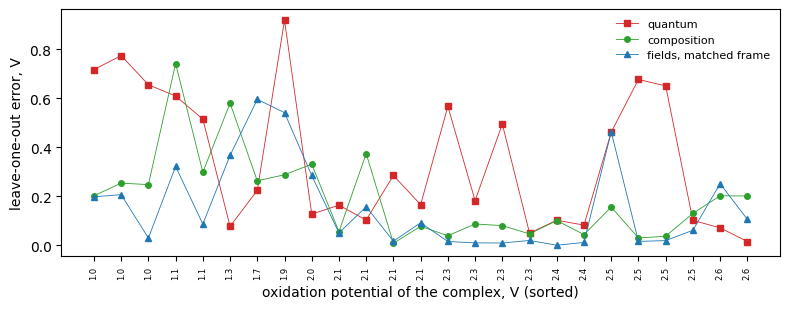

rank correlation of the errors of two models: composition and fields +0.73, population analysis and fields +0.07
composition : 5 of its five largest errors are among the 11 complexes of the lowest potential
fields, matched frame: 4 of its five largest errors are among the 11 complexes of the lowest potential
quantum     : 4 of its five largest errors are among the 11 complexes of the lowest potential


In [12]:
order = np.argsort(nickel_y["E_ox_AN"])
fig, ax = plt.subplots(figsize=(8.0, 3.2))
for model, colour, marker in (("quantum", "tab:red", "s"), ("composition", "tab:green", "o"), ("physchem", "tab:blue", "^")):
    errors = np.array(ox["leave-one-out"][model]["abs_errors"])[order]
    ax.plot(range(len(order)), errors, marker + "-", ms=4, lw=0.6, color=colour, label=model_names[model])
ax.set_xticks(range(len(order)))
ax.set_xticklabels(["%.1f" % v for v in nickel_y["E_ox_AN"][order]], fontsize=6, rotation=90)
ax.set_xlabel("oxidation potential of the complex, V (sorted)")
ax.set_ylabel("leave-one-out error, V")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()


def ranks(values):
    return np.argsort(np.argsort(values))


errors = {m: np.array(ox["leave-one-out"][m]["abs_errors"]) for m in ("composition", "physchem", "quantum")}
print("rank correlation of the errors of two models: composition and fields %+.2f, population analysis and fields %+.2f" % (
    np.corrcoef(ranks(errors["composition"]), ranks(errors["physchem"]))[0, 1],
    np.corrcoef(ranks(errors["quantum"]), ranks(errors["physchem"]))[0, 1]))
lowest = ranks(nickel_y["E_ox_AN"]) < 11
for m, errs in errors.items():
    print("%-12s: %d of its five largest errors are among the 11 complexes of the lowest potential" % (
        model_names[m], int(np.sum(lowest[np.argsort(-errs)[:5]]))))

All three models fail most for the complexes of low potential. The errors of the composition and of
the fields go together: they fail at the same complexes. The errors of the population analysis have
no relation to theirs, and they are larger.

Now the other couple. Its potential varies by 0.06 V.

In [13]:
print("the reduction potential of the nickel complexes: mean absolute error in volts")
red = show("E_red_AN", nickel_y["E_red_AN"])
p = paired("composition", "invariant", red["leave-one-out"])
print()
print("fields, no frame, against the composition, leave-one-out: %+.3f V [%+.3f, %+.3f]" % (p["mean"], p["low"], p["high"]))

the reduction potential of the nickel complexes: mean absolute error in volts


                                      leave-one-out          five random folds
                              error, V           R2      error, V           R2
the training mean                0.049                      0.050
composition                      0.046       +0.053         0.048       +0.003
quantum                          0.041       -0.239         0.043       -0.059
site                             0.047       +0.012         0.047       -0.003
fields, no frame                 0.031       +0.418         0.031       +0.340
fields, matched frame            0.033       +0.202         0.029       +0.215
fields, rule frame               0.043       +0.051         0.042       +0.024

fields, no frame, against the composition, leave-one-out: +0.015 V [+0.003, +0.028]


The training mean predicts with an error of 0.049 V, and the best model, the fields without a frame,
with 0.031 V (R² +0.42). The fields are better than the composition, by 0.015 V with an interval
that excludes zero. But the target varies by 0.06 V, and the best model leaves an error of half of
that. Nothing here is worth using.

## Iron: 2216 complexes that share only the metal

Here the series is large and the complexes share nothing but the metal. Three models are run in
this notebook, on the whole series: the composition, the first sphere alone (`site`) and the
kernel without a frame. Two designs are used. The **random folds** are five folds of complexes.
The **unseen-sphere folds** keep every first coordination sphere whole inside one fold, so that
no sphere of a test fold was in the training. The easy way to predict a redox potential is to
recognise the coordination, and the second design takes that away.

The overlap kernel in a frame needs about an hour for this series. Its two rows are read from the
stored results of the benchmark: `overlap, file's frame` is the kernel in the frame that each
file happens to carry, and `overlap, rule frame` the same kernel after every complex has been put
in the frame of its metal and principal axes.

In [14]:
import time
from cmfqsar.invariant import AutocorrelationSpec, autocorrelation_kernel, feature_matrix

t0 = time.time()
elements_iron = rm.element_columns(iron)
fs = FieldSet.create(physchem=list(rm.FIELDS), alpha=1.0, charge_model="gasteiger", param_scheme="rdkit")
spec = AutocorrelationSpec()
kernel_iron = autocorrelation_kernel(feature_matrix([build_fields(m, fs, n) for m, n in zip(iron, iron_names)], spec),
                                     n_bins=spec.n_bins)
live = {"composition": rm.prepare("composition", iron, iron_names, elements_iron),
        "site": rm.prepare("site", iron, iron_names, elements_iron),
        "invariant": {1.0: kernel_iron}}
print("the kernel without a frame for %d complexes: %.0f s" % (len(iron), time.time() - t0))

iron_designs = {"random folds": rm.random_folds(len(y_iron)), "unseen-sphere folds": rm.sphere_folds(spheres)}
found = {d: {m: score(entry, y_iron, design) for m, entry in live.items()} for d, design in iron_designs.items()}

the kernel without a frame for 2216 complexes: 9 s


In [15]:
import json

with open("benchmarks/results/metal/iron.json", encoding="utf-8") as fh:
    stored = json.load(fh)
names_iron = {"composition": "composition", "site": "site (first sphere alone)", "invariant": "fields, no frame",
              "overlap-raw": "overlap, file's frame", "overlap-rule": "overlap, rule frame"}
keys = {"random folds": "random", "unseen-sphere folds": "unseen-sphere"}
print("mean absolute error in volts; the training mean predicts %.3f V (random) and %.3f V (unseen spheres)" % (
    stored["designs"]["random"]["baseline_mae"], stored["designs"]["unseen-sphere"]["baseline_mae"]))
print("%-26s %20s %20s   %s" % ("", "random folds", "unseen-sphere folds", "from"))
print("%-26s %9s %10s %9s %10s" % ("", "error, V", "R2", "error, V", "R2"))
for m, label in names_iron.items():
    cols = []
    for d in iron_designs:
        rec = found[d][m] if m in live else stored["designs"][keys[d]]["models"][m]
        cols.append((rec["mae_mean"], rec["r2_pooled"]))
    print("%-26s %9.3f %+10.3f %9.3f %+10.3f   %s" % (label, cols[0][0], cols[0][1], cols[1][0], cols[1][1],
                                                     "this notebook" if m in live else "stored results"))

mean absolute error in volts; the training mean predicts 0.523 V (random) and 0.523 V (unseen spheres)
                                   random folds  unseen-sphere folds   from
                            error, V         R2  error, V         R2
composition                    0.313     +0.566     0.336     +0.507   this notebook
site (first sphere alone)      0.359     +0.447     0.398     +0.348   this notebook
fields, no frame               0.254     +0.690     0.285     +0.629   this notebook
overlap, file's frame          0.490     +0.083     0.499     +0.043   stored results
overlap, rule frame            0.302     +0.588     0.316     +0.550   stored results


In [16]:
print("%-56s %26s %26s" % ("difference of the errors, V [95 % interval]", "random folds", "unseen-sphere folds"))
for a, b in (("composition", "invariant"), ("site", "composition")):
    text = []
    for d in iron_designs:
        p = paired(a, b, found[d])
        text.append("%+.3f [%+.3f, %+.3f]" % (p["mean"], p["low"], p["high"]))
    print("%-56s %26s %26s" % (names_iron[b] + " against " + names_iron[a], text[0], text[1]))
for label in ("overlap-rule vs overlap-raw", "overlap-rule vs composition", "invariant vs overlap-rule"):
    text = []
    for d in ("random", "unseen-sphere"):
        p = stored["designs"][d]["pairs"][label]
        text.append("%+.3f [%+.3f, %+.3f]" % (p["mean"], p["low"], p["high"]))
    first, second = label.split(" vs ")
    print("%-56s %26s %26s   stored" % (names_iron[second] + " against " + names_iron[first], text[0], text[1]))

difference of the errors, V [95 % interval]                            random folds        unseen-sphere folds
fields, no frame against composition                        +0.059 [+0.049, +0.071]    +0.054 [+0.043, +0.067]
composition against site (first sphere alone)               +0.046 [+0.037, +0.055]    +0.060 [+0.052, +0.069]
overlap, file's frame against overlap, rule frame           +0.188 [+0.173, +0.202]    +0.181 [+0.167, +0.197]   stored
composition against overlap, rule frame                     +0.012 [+0.001, +0.022]    +0.021 [+0.009, +0.033]   stored
overlap, rule frame against fields, no frame                +0.049 [+0.039, +0.058]    +0.034 [+0.024, +0.044]   stored


Four readings.

- **The composition says more than half.** It predicts with 0.31 V where the training mean gives
  0.52 V (R² +0.57). Element counts and the first sphere decide most of a redox potential.
- **The fields without a frame beat the composition**, by +0.059 V, and the interval excludes zero.
  With whole spheres held out the order is the same, +0.054 V. On a large series the fields beat
  the composition. (On the nickel series, with 25 complexes, this could not be shown.)
- **The file's frame is worth nothing, and a rule frame is worth a lot.** The overlap kernel in the
  frame that the file carries has an R² of +0.08: it has learned almost nothing. After every complex
  is put in the frame of its own metal and principal axes it reaches +0.59. The frame is worth
  +0.188 V.
- **A frame is still worse than no frame.** The overlap kernel in the rule frame is only just better
  than the composition (+0.012 V, an interval that excludes zero by little), and the kernel without
  a frame is better than it by +0.049 V. When the complexes share nothing but the metal, a rule frame
  is far better than none, a little better than no geometry, and worse than not needing a frame.

The numbers of the kernel without a frame differ from the stored ones by less than 0.001 V
(0.2538 V against 0.2530 V with random folds). The code of the commit that stored them gives the
stored numbers exactly, so the difference comes from later changes of the program. The kernel without
a frame was one of the things that changed, on 7 and 9 November.

## What the model reads

The stored co-field of the oxidation potential of the nickel series, fitted to all 25 complexes,
says where the five fields have their largest weights, measured from the nickel atom.

In [17]:
with open("benchmarks/results/metal/cofield.json", encoding="utf-8") as fh:
    cofield = json.load(fh)
print("%-16s %10s %26s" % ("field", "peak", "distance from the metal, A"))
for row in cofield["E_ox_AN"]:
    print("%-16s %+10.3f %26.2f" % (row["field"], row["peak"], row["distance_from_metal"]))

field                  peak distance from the metal, A
Electrostatic        -0.201                       6.70
Steric               -0.125                       7.33
Hydrophobic          +0.179                       4.52
H-bond acceptor      -0.349                       5.60
H-bond donor         +0.056                       3.09


The weights lie 3 to 7 Å from the metal, out among the substituents. They do not lie at the metal
and not on its donors. That is the right place for this series: every member has the same metal and
the same six donors, so nothing at the metal can tell two of them apart. What differs is the
substituent. It is also where the composition looks, through the number of nitrogen atoms. The
co-field shows where the fields look. It does not show that the fields are needed.

## What to take from this notebook

- A metal atom can make a program run and return numbers that mean nothing. Three checks take a
  second each: the electrostatic charges are not "not a number" (the charge source is not plain
  `gasteiger`), the formal charges add up to the charge of the complex, and the metal has a radius
  of its own.
- The metal is the one atom that every complex has, so it gives the origin of a frame. For a series
  with one coordination sphere, match the donors. For a diverse series use the rule, and look at
  the gap that tells whether it is arbitrary.
- Put the composition in the references. On the nickel series it reaches an R² of 0.78 where the
  fields reach 0.82, and the gate of the manual's study (item EC4) compared the fields only with
  numbers of the calculation and with the first sphere. On the iron series the fields are better than
  the composition by 0.06 V, with an interval that excludes zero.
- The model without a frame is the best of the field models on the diverse series, and equal to
  the framed ones on the series with one skeleton. A rule frame is worth a lot against the arbitrary
  frame of a file, and nothing against no frame.
- The potentials are computed. These results say how well a description orders what one calculation
  produced. They do not say how well it predicts a measurement.
- With 25 complexes the intervals are wide, and a design can change an answer. Every difference above
  is given with its interval, and with two designs.

The stages can be run again with `python benchmarks/run_metal.py --stage nickel` (24 seconds) and
`--stage iron` (about an hour).

Where to read further in the manual: *A metal in the middle: coordination complexes* has the
three faults, the two frames and the measurement of both series. *Three tests to run before you
build a new field or a new score* gives the kind of question that this notebook asks of the
composition.